In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# Puente de Wheatstone
g = nx.DiGraph() # crear grafos dirigidos

# agregar conexiones al grafo
g.add_edge(0, 1, R=2.0, E=10.0)   # e1, fuente real
g.add_edge(1, 2, R=4.0)           # e2
g.add_edge(1, 3, R=8.0)           # e3
g.add_edge(2, 3, R=10.0)          # e4, puente
g.add_edge(2, 0, R=2.0)           # e5
g.add_edge(3, 0, R=4.0)           # e6

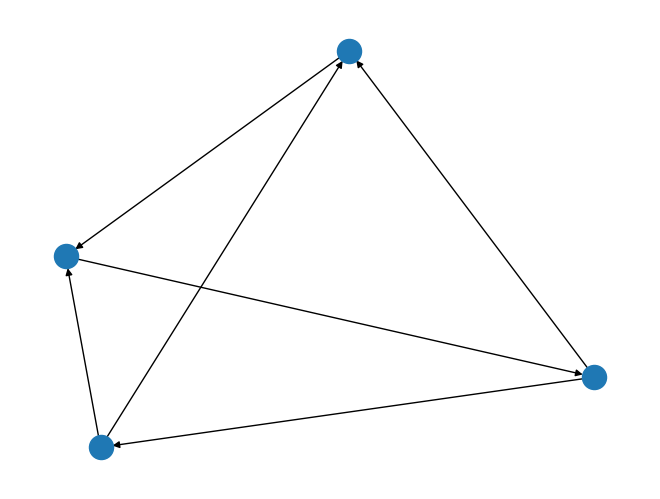

In [ ]:
nx.draw(g)

In [ ]:
A = nx.incidence_matrix(g, oriented=True).toarray()
print(A)

[[-1.  0.  0.  0.  1.  1.]
 [ 1. -1. -1.  0.  0.  0.]
 [ 0.  1.  0. -1. -1.  0.]
 [ 0.  0.  1.  1.  0. -1.]]


In [ ]:
nodes = list(g.nodes)
links = list(g.edges)
G = np.diag([ 1/g.edges[li]["R"] for li in links])

In [ ]:
1/g.edges[(0,1)]["R"]

0.5

In [ ]:
def solve_circuit(g):
    # sacar nodos y links
    nodes = list(g.nodes)
    edges = list(g.edges)

    # matrix de incidencia del grafo
    A = nx.incidence_matrix( g, oriented=True ).toarray()
    # Matriz de impedancias
    G = np.diag([ 1.0/g.edges[ei]["R"] for ei in edges])
    # Vector de fuentes
    E = np.array([ g.edges[ei].get("E", 0.0) for ei in edges])

    # crear el sistema lineal
    L = A @ G @ A.T
    J = -A @ G @ E

    # resolver el sistema
    phi = np.zeros(len(nodes)) # vector de incognitas
    phi[1:] = np.linalg.solve(L[1:, 1:], J[1:] )

    # devolver la transformacion
    v = A.T @ phi
    i = G @ (v + E)

    return {
        "phi": dict(zip(nodes, phi)),
        "v": dict(zip(edges, v)),
        "i": dict(zip(edges, i)),
    }

In [ ]:
res = solve_circuit(g)

print(">> Potenciales nodales")
for ni, pi in res["phi"].items():
    print(f"  phi_{ni} = {pi:.4f} V")

print(">> Voltajes")
for li, vi in res["v"].items():
    print(f"  {li}: {vi:.4f} V")

print(">> Corrientes")
for li, vi in res["i"].items():
    print(f"  {li}: {vi:+.4f} A")

>> Potenciales nodales
  phi_0 = 0.0000 V
  phi_1 = -6.6667 V
  phi_2 = -2.2222 V
  phi_3 = -2.2222 V
>> Voltajes
  (0, 1): -6.6667 V
  (1, 2): 4.4444 V
  (1, 3): 4.4444 V
  (2, 3): -0.0000 V
  (2, 0): 2.2222 V
  (3, 0): 2.2222 V
>> Corrientes
  (0, 1): +1.6667 A
  (1, 2): +1.1111 A
  (1, 3): +0.5556 A
  (2, 3): -0.0000 A
  (2, 0): +1.1111 A
  (3, 0): +0.5556 A
